In [16]:
import torch
import sar_clip
import torch.nn.functional as F

In [17]:
#download model to ./sar_clip/model_configs
model_name = 'RN101' #select from ['RN50', 'RN101', 'ViT-B-16', 'ViT-B-32', 'ViT-L-14']
model_path = r'./sar_clip/model_configs/RN101/rn101_model.safetensors'
cache_dir= r"./sar_clip/model_configs/RN101"
model = sar_clip.create_model_with_args(model_name, pretrained=model_path)
model.eval()
tokenizer = sar_clip.get_tokenizer(model_name, cache_dir=cache_dir)

In [3]:
%cd /liuwenchu/code/detection/SARCLIP/

/liuwenchu/code/detection/SARCLIP


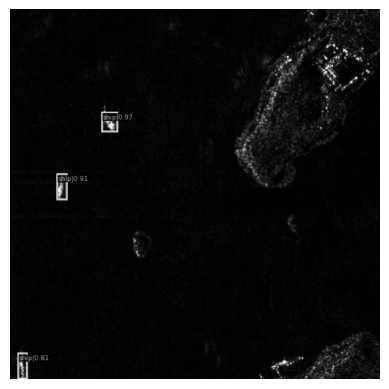

Resized shape: torch.Size([1, 3, 224, 224])


In [28]:
# Load image and tokenize text
image_path = r"./0000371.jpg"
image = sar_clip.readtif(image_path)
sar_clip.display(image)
image = torch.from_numpy(image)
image = image.unsqueeze(0)
image = F.interpolate(image, size=(224, 224), mode='bicubic', align_corners=False)
# 检查一下现在的尺寸，应该是 torch.Size([1, 3, 224, 224])
print("Resized shape:", image.shape)
# text = [
#     "an SAR image of urban zones",
#     "an SAR image of mountainous areas",
#     "an SAR image of water areas",
#     "an SAR image of croplands",
#     "an SAR image of harbor",
#     "one solitary marine craft is visible in the right region .",
#     "along the right side , several storage tanks are be detected .",
#     "1 aircraft is found throughout the frame ."
# ]
text = [
    "an SAR image of car",
    "an SAR image of ship",
    "an SAR image of tank",
    "an SAR image of aircraft",
    "an SAR image of harbor",
    "an SAR image of bridge",
]
tokenized_text = tokenizer(text)

In [29]:
# Perform inference with the model
with torch.no_grad(), torch.cuda.amp.autocast():
    image_features = model.encode_image(image)
    text_features = model.encode_text(tokenized_text)
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)

    text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)

In [30]:
# Format the output as requested, with the probabilities rounded to 4 decimal places
formatted_output = [
    f"{label:<50} {prob:.4f}"
    for label, prob in zip(text, text_probs[0].numpy())
]

# Print the formatted predictions
print("Predictions:")
for line in formatted_output:
    print(line)

Predictions:
an SAR image of car                                0.0021
an SAR image of ship                               0.9091
an SAR image of tank                               0.0005
an SAR image of aircraft                           0.0014
an SAR image of harbor                             0.0867
an SAR image of bridge                             0.0001
